In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("weather_data.csv")

In [ ]:
df.shape


(96453, 14)

This dataset contains 96,453 rows and 14 columns. Each row represents a weather observation with different measurements such as temperature, humidity, wind speed and pressure.


In [ ]:
df.columns

Index(['Formatted Date', 'Time', 'Summary', 'Precip Type', 'Temperature (C)',
       'Apparent Temperature (C)', 'Wind Speed (km/h)',
       'Wind Bearing (degrees)', 'Visibility (km)', 'Pressure (millibars)',
       'Humidity', 'Month', 'Day', 'Year'],
      dtype='object')

The dataset contains 14 columns covering date, time, weather conditions, temperature, wind, visibility, pressure and humidity.

In [ ]:
df.dtypes

,0
Formatted Date,object
Time,object
Summary,object
Precip Type,object
Temperature (C),float64
Apparent Temperature (C),float64
Wind Speed (km/h),float64
Wind Bearing (degrees),float64
Visibility (km),float64
Pressure (millibars),float64


This output shows the data type of each column. Numerical columns contain weather measurements, while date, time and weather descriptions are stored as object data types.

In [ ]:
df.describe()

,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Day,Year
count,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.000000,96453.00000,96453.000000
mean,11.932678,10.855029,10.810640,187.509232,10.347325,1003.235956,0.734899,6.523799,15.72708,2011.000404
std,9.551546,10.696847,6.913571,107.383428,4.192123,116.969906,0.195473,3.448495,8.80216,3.162142
min,-21.822222,-27.716667,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.00000,2006.000000
25%,4.688889,2.311111,5.828200,116.000000,8.339800,1011.900000,0.600000,4.000000,8.00000,2008.000000
50%,12.000000,12.000000,9.965900,180.000000,10.046400,1016.450000,0.780000,7.000000,16.00000,2011.000000
75%,18.838889,18.838889,14.135800,290.000000,14.812000,1021.090000,0.890000,10.000000,23.00000,2014.000000
max,39.905556,39.344444,63.852600,359.000000,16.100000,1046.380000,1.000000,12.000000,31.00000,2016.000000


Descriptive statistics summarize the numerical columns using count, mean, standard deviation, minimum, maximum and quartile values. This helps us understand the overall distribution of weather measurements.

In [ ]:
df["Formatted Date"] = pd.to_datetime(
    df["Formatted Date"],
    errors="coerce",
    utc=True
)

The date column was originally stored as text. We converted it into a datetime format so that we can perform time-based analysis and create weather trend graphs.

In [ ]:
print("First Date:", df["Formatted Date"].min())
print("Last Date:", df["Formatted Date"].max())

First Date: 2006-01-01 00:00:00+00:00
Last Date: 2016-12-31 00:00:00+00:00


This identifies the starting and ending dates covered by the dataset and helps us understand its historical time period.

In [ ]:
print("Number of Years:", df["Year"].nunique())
print("Number of Months:", df["Month"].nunique())

Number of Years: 11
Number of Months: 12


This shows how many different years and months are represented in the dataset.

In [ ]:
selected_columns = [
    "Formatted Date",
    "Time",
    "Summary",
    "Precip Type",
    "Temperature (C)",
    "Apparent Temperature (C)",
    "Wind Speed (km/h)",
    "Wind Bearing (degrees)",
    "Visibility (km)",
    "Pressure (millibars)",
    "Humidity",
    "Month",
    "Year"
]

df = df[selected_columns].copy()

df.head()

,Formatted Date,Time,Summary,Precip Type,Temperature (C),Apparent Temperature (C),Wind Speed (km/h),Wind Bearing (degrees),Visibility (km),Pressure (millibars),Humidity,Month,Year
0,2006-04-01 00:00:00+00:00,00:00:00.000,Partly Cloudy,rain,9.472222,7.388889,14.1197,251.0,15.8263,1015.13,0.89,4,2006
1,2006-04-01 00:00:00+00:00,01:00:00.000,Partly Cloudy,rain,9.355556,7.227778,14.2646,259.0,15.8263,1015.63,0.86,4,2006
2,2006-04-01 00:00:00+00:00,02:00:00.000,Mostly Cloudy,rain,9.377778,9.377778,3.9284,204.0,14.9569,1015.94,0.89,4,2006
3,2006-04-01 00:00:00+00:00,03:00:00.000,Partly Cloudy,rain,8.288889,5.944444,14.1036,269.0,15.8263,1016.41,0.83,4,2006
4,2006-04-01 00:00:00+00:00,04:00:00.000,Mostly Cloudy,rain,8.755556,6.977778,11.0446,259.0,15.8263,1016.51,0.83,4,2006


We selected the columns relevant to our analysis, including weather measurements, weather conditions and time information. The location column is not available in this dataset, so we will focus on weather patterns over time instead of geographical comparisons.

Missing Values:

We checked the dataset for missing values to identify incomplete records before performing further analysis. This helps ensure the accuracy and reliability of our results

In [ ]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Formatted Date                0
Time                          0
Summary                       0
Precip Type                 517
Temperature (C)               0
Apparent Temperature (C)      0
Wind Speed (km/h)             0
Wind Bearing (degrees)        0
Visibility (km)               0
Pressure (millibars)          0
Humidity                      0
Month                         0
Year                          0
dtype: int64


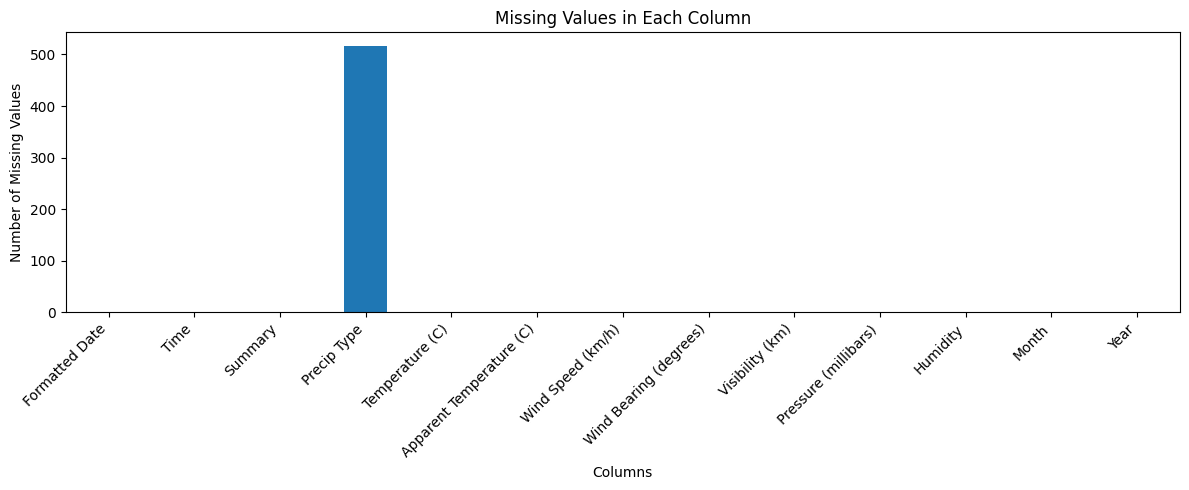

In [ ]:
plt.figure(figsize=(12, 5))

missing_values.plot(kind="bar")

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

The graph shows that missing values are only present in the Precip Type column, while all other columns have complete data. This means the dataset has relatively few missing values.

Since Precip Type is a categorical column, filling its missing values with a median is not possible. We decided to remove the 517 records with missing precipitation types because they represent a very small percentage of the dataset. No treatment was required for the remaining columns.

In [ ]:
clean_df = df.copy()

clean_df = clean_df.dropna(subset=["Precip Type"])

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", clean_df.shape)

print("\nMissing Values After Cleaning:")
print(clean_df.isnull().sum())

Original Dataset Shape: (96453, 13)
Cleaned Dataset Shape: (95936, 13)

Missing Values After Cleaning:
Formatted Date              0
Time                        0
Summary                     0
Precip Type                 0
Temperature (C)             0
Apparent Temperature (C)    0
Wind Speed (km/h)           0
Wind Bearing (degrees)      0
Visibility (km)             0
Pressure (millibars)        0
Humidity                    0
Month                       0
Year                        0
dtype: int64


Repeated Values(Duplicates):

Duplicate records can affect the accuracy of data analysis. We will check whether the dataset contains identical rows and remove any unnecessary duplicates.

In [ ]:
duplicate_count = clean_df.duplicated().sum()

print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 24


In [ ]:
repeated_dates = clean_df.duplicated(
    subset=["Formatted Date", "Time"]
).sum()

print("Repeated Date-Time Records:", repeated_dates)

Repeated Date-Time Records: 34


In [ ]:
clean_df = clean_df.drop_duplicates(
    subset=["Formatted Date", "Time"]
)

print("Dataset Shape After Duplicate Removal:", clean_df.shape)

Dataset Shape After Duplicate Removal: (95902, 13)


We checked the dataset for identical rows and repeated date-time records. Any repeated observations were removed to prevent duplicate data from affecting the analysis

Outlier Detection:

We use outlier detection to identify unusually high or low weather measurements. Box plots and histograms help us understand the distribution of the data and identify extreme values. However, extreme weather measurements may represent actual weather events, so they should not be removed without proper investigation.

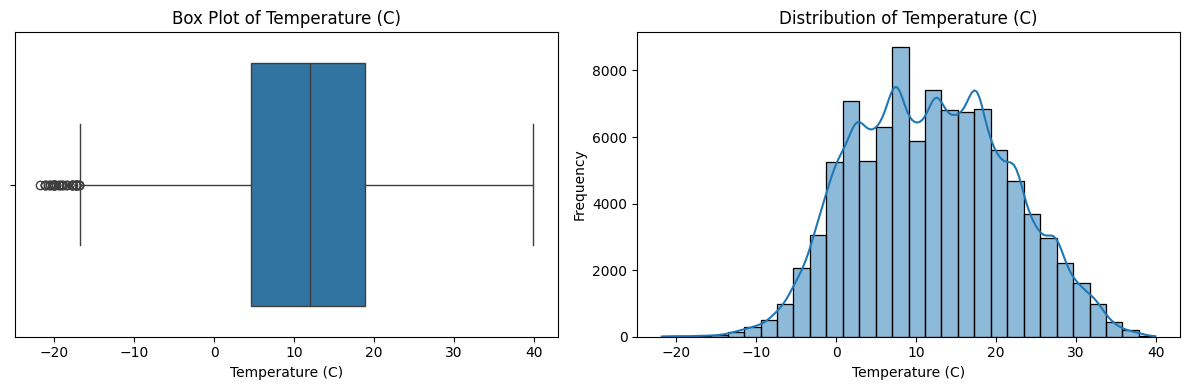

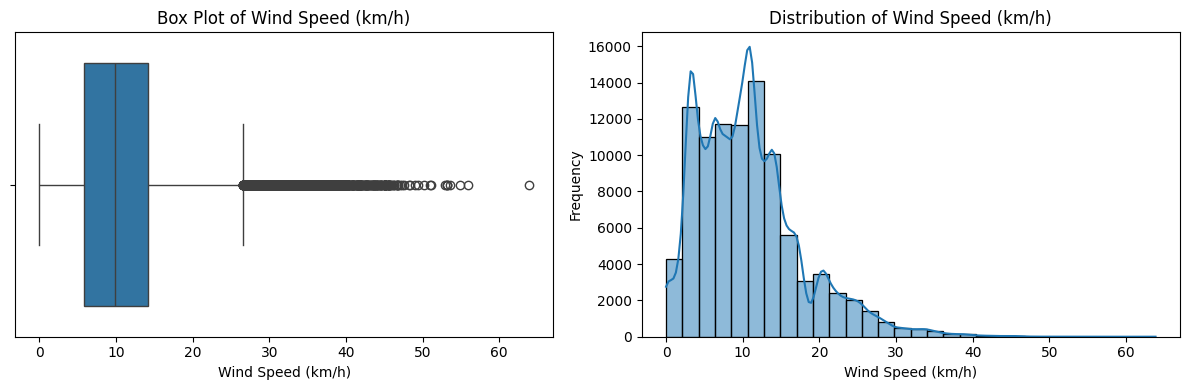

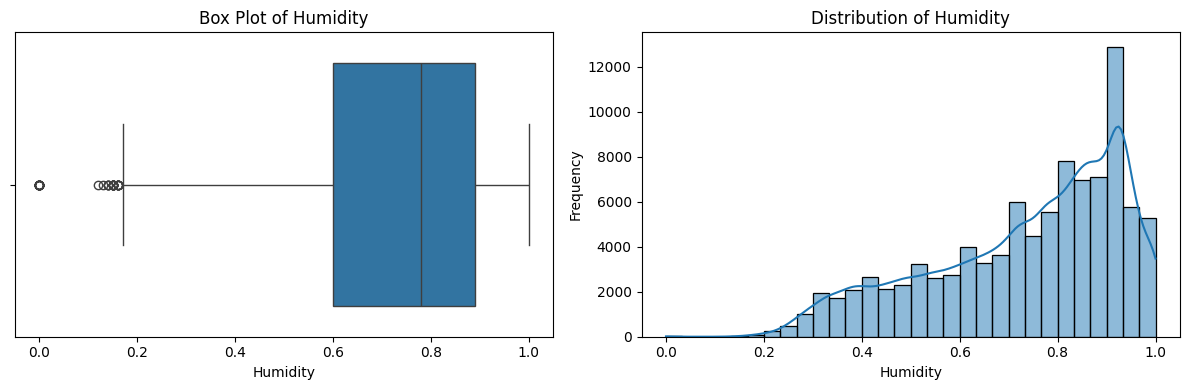

In [ ]:
weather_columns = [
    "Temperature (C)",
    "Wind Speed (km/h)",
    "Humidity"
]

for column in weather_columns:

    plt.figure(figsize=(12, 4))

    plt.subplot(1, 2, 1)
    sns.boxplot(x=clean_df[column])
    plt.title(f"Box Plot of {column}")
    plt.xlabel(column)

    plt.subplot(1, 2, 2)
    sns.histplot(clean_df[column], bins=30, kde=True)
    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

The box plots help identify extreme weather measurements, while the histograms show how frequently different values occur. These visualizations provide an overview of temperature, wind speed and humidity distributions.

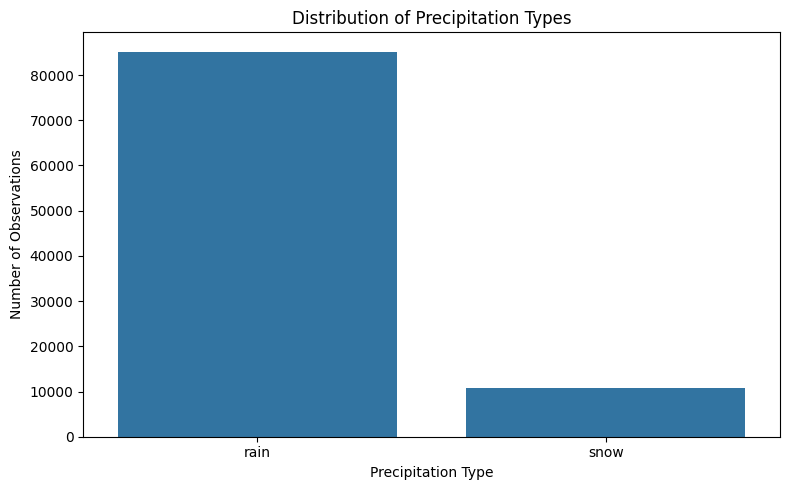

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=clean_df,
    x="Precip Type"
)

plt.title("Distribution of Precipitation Types")
plt.xlabel("Precipitation Type")
plt.ylabel("Number of Observations")

plt.tight_layout()
plt.show()

This graph compares the frequency of different precipitation types recorded in the dataset. Since the dataset does not contain numerical rainfall measurements, we use precipitation categories to understand the recorded types of precipitation.

In [ ]:
columns_to_check = [
    "Temperature (C)",
    "Wind Speed (km/h)"
]

for column in columns_to_check:

    Q1 = clean_df[column].quantile(0.25)
    Q3 = clean_df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = clean_df[
        (clean_df[column] < lower_limit) |
        (clean_df[column] > upper_limit)
    ]

    print("Column:", column)
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))



Column: Temperature (C)
Lower Limit: -16.7770833275
Upper Limit: 40.2173611005
Number of Outliers: 39
Column: Wind Speed (km/h)
Lower Limit: -6.673449999999998
Upper Limit: 26.62135
Number of Outliers: 3010


In [ ]:
for column in columns_to_check:

    print("\nColumn:", column)

    print("\nLowest Values:")
    print(clean_df.nsmallest(5, column)[
        ["Formatted Date", column, "Summary"]
    ])

    print("\nHighest Values:")
    print(clean_df.nlargest(5, column)[
        ["Formatted Date", column, "Summary"]
    ])


Column: Temperature (C)

Lowest Values:
                 Formatted Date  Temperature (C) Summary
54847 2012-02-10 00:00:00+00:00       -21.822222   Foggy
55490 2012-02-09 00:00:00+00:00       -21.111111   Foggy
55493 2012-02-09 00:00:00+00:00       -21.111111   Foggy
55494 2012-02-09 00:00:00+00:00       -21.111111   Foggy
55495 2012-02-09 00:00:00+00:00       -20.783333   Foggy

Highest Values:
                 Formatted Date  Temperature (C)        Summary
12759 2007-07-22 00:00:00+00:00        39.905556          Clear
12737 2007-07-21 00:00:00+00:00        39.588889  Partly Cloudy
12664 2007-07-19 00:00:00+00:00        38.983333  Partly Cloudy
12711 2007-07-20 00:00:00+00:00        38.983333  Partly Cloudy
12712 2007-07-20 00:00:00+00:00        38.983333  Partly Cloudy

Column: Wind Speed (km/h)

Lowest Values:
                Formatted Date  Wind Speed (km/h)        Summary
381  2006-04-23 00:00:00+00:00                0.0  Partly Cloudy
390  2006-04-24 00:00:00+00:00             

The IQR method identified some extreme weather measurements in temperature and wind speed. However, extreme values may represent genuine weather conditions such as heatwaves, cold periods or strong winds. Therefore, we decided to retain these values instead of removing them without further evidence that they were errors.

Univariate Analysis:

Univariate analysis is used to study one variable at a time. We will examine the distribution of temperature, humidity and wind speed using histograms and descriptive statistics. This helps us understand the typical values, spread and patterns of individual weather measurements.


Analysis of: Temperature (C)
count    95902.000000
mean        11.938530
std          9.569906
min        -21.822222
25%          4.595833
50%         12.027778
75%         18.844444
max         39.905556
Name: Temperature (C), dtype: float64


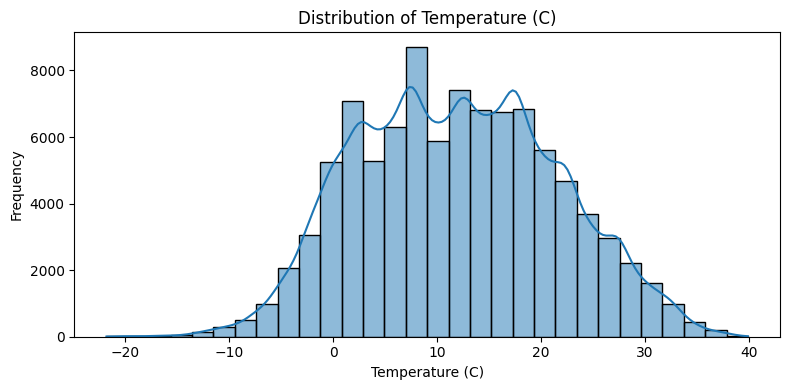


Analysis of: Humidity
count    95902.000000
mean         0.734824
std          0.195716
min          0.000000
25%          0.600000
50%          0.780000
75%          0.890000
max          1.000000
Name: Humidity, dtype: float64


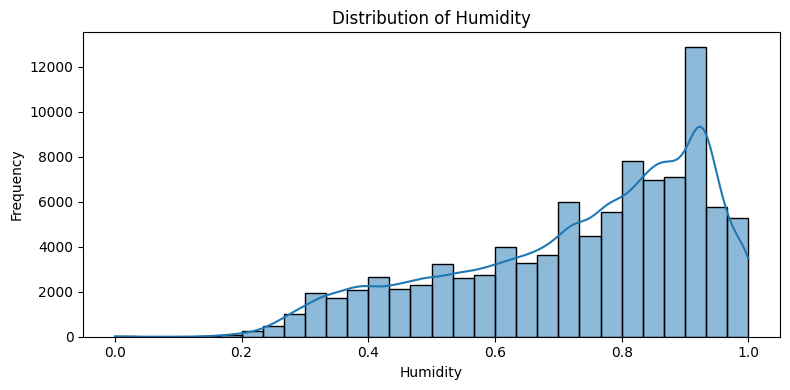


Analysis of: Wind Speed (km/h)
count    95902.000000
mean        10.807226
std          6.920275
min          0.000000
25%          5.812100
50%          9.933700
75%         14.135800
max         63.852600
Name: Wind Speed (km/h), dtype: float64


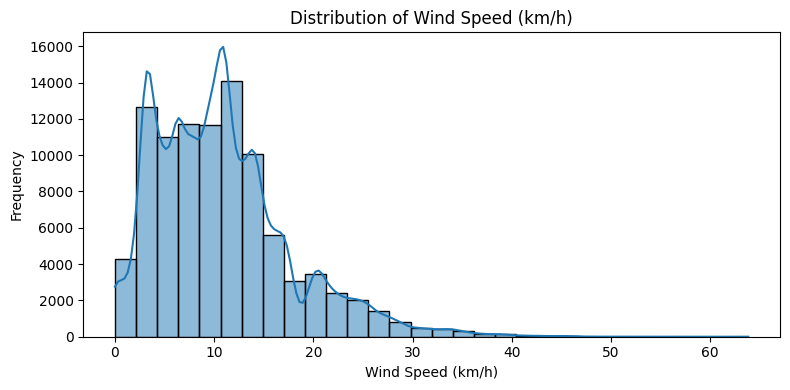

In [ ]:
univariate_columns = [
    "Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)"
]

for column in univariate_columns:

    print("\nAnalysis of:", column)
    print(clean_df[column].describe())

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=clean_df,
        x=column,
        bins=30,
        kde=True
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

**Temperature:** The average temperature is approximately 11.94°C, while the median is 12.03°C. The recorded temperatures range from -21.82°C to 39.91°C. This shows that the dataset contains both very cold and very warm weather conditions.

**Humidity:** The average humidity is approximately 0.735 (73.5%), with a median of 0.78 (78%). Humidity ranges from 0 to 1, indicating that the dataset includes observations from very dry to fully humid conditions. Most observations show relatively high humidity.

**Wind Speed:** The average wind speed is approximately 10.81 km/h, while the median is 9.93 km/h. Most observations have relatively moderate wind speeds, although some much higher values are present, reaching 63.85 km/h.

Bivariate Analysis:

Bivariate analysis helps us understand the relationship between two weather variables. We will use scatter plots and correlation analysis to examine how temperature relates to humidity and how actual temperature compares with apparent temperature.

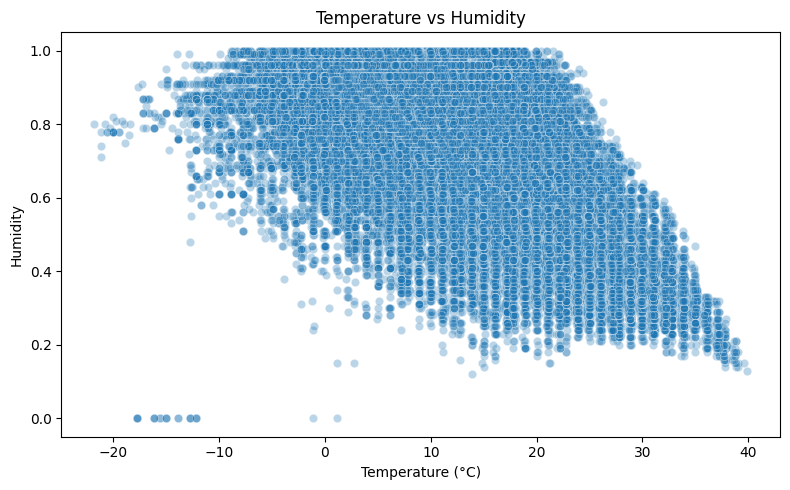

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="Temperature (C)",
    y="Humidity",
    alpha=0.3
)

plt.title("Temperature vs Humidity")
plt.xlabel("Temperature (°C)")
plt.ylabel("Humidity")

plt.tight_layout()
plt.show()

In [ ]:
correlation = clean_df["Temperature (C)"].corr(
    clean_df["Humidity"]
)

print("Temperature and Humidity Correlation:", correlation)

Temperature and Humidity Correlation: -0.6322161081494543


The correlation between temperature and humidity is approximately -0.63, indicating a moderately strong negative relationship. This means that as temperature increases, humidity generally tends to decrease. However, this relationship does not mean that temperature directly causes humidity to decrease.

Temperature and Apparent Temperature Correlation: 0.9926350079609437


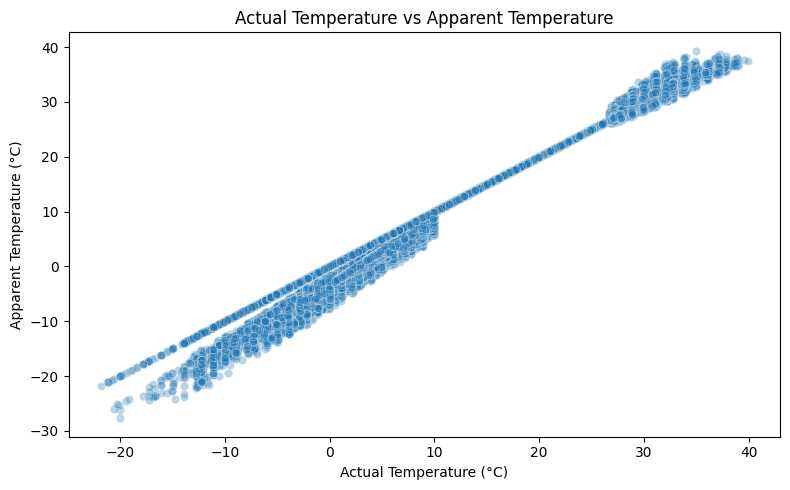

In [ ]:
correlation = clean_df["Temperature (C)"].corr(
    clean_df["Apparent Temperature (C)"]
)

print("Temperature and Apparent Temperature Correlation:", correlation)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=clean_df,
    x="Temperature (C)",
    y="Apparent Temperature (C)",
    alpha=0.3
)

plt.title("Actual Temperature vs Apparent Temperature")
plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Apparent Temperature (°C)")

plt.tight_layout()
plt.show()

The correlation between actual temperature and apparent temperature is approximately 0.99, indicating an extremely strong positive relationship. This shows that both measurements follow almost the same pattern. Although apparent temperature may differ slightly from actual temperature due to factors such as wind and humidity, they remain very closely related.

Correlation Analysis:

A correlation heatmap is used to show the strength and direction of relationships between numerical weather variables. It helps identify which variables are positively or negatively related to each other.

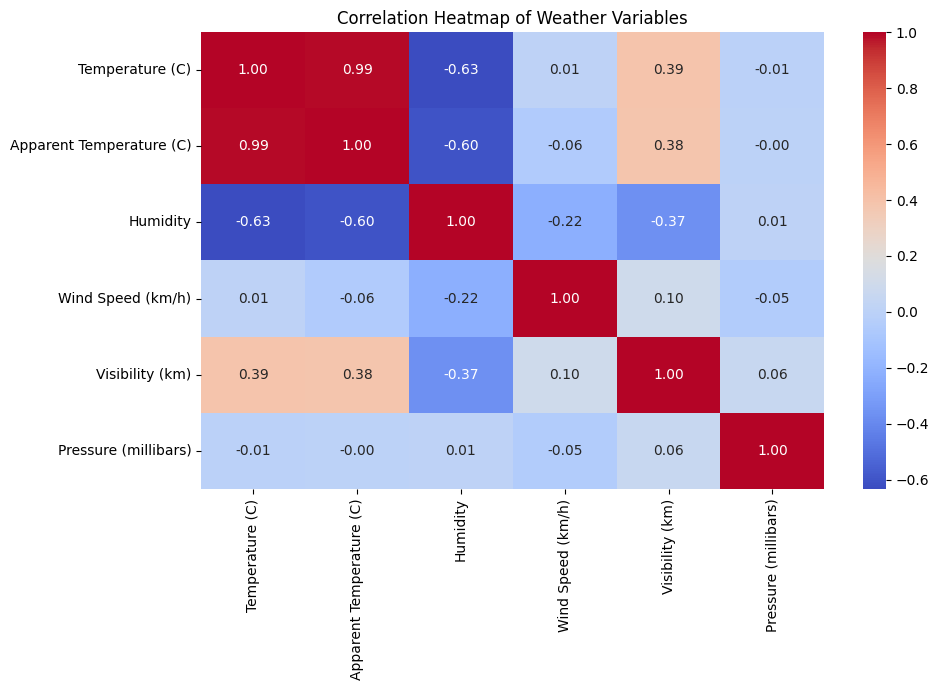

In [ ]:
correlation_columns = [
    "Temperature (C)",
    "Apparent Temperature (C)",
    "Humidity",
    "Wind Speed (km/h)",
    "Visibility (km)",
    "Pressure (millibars)"
]

correlation_matrix = clean_df[correlation_columns].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Weather Variables")
plt.tight_layout()
plt.show()

In [ ]:
print(correlation_matrix.round(2))

                          Temperature (C)  Apparent Temperature (C)  Humidity  \
Temperature (C)                      1.00                      0.99     -0.63   
Apparent Temperature (C)             0.99                      1.00     -0.60   
Humidity                            -0.63                     -0.60      1.00   
Wind Speed (km/h)                    0.01                     -0.06     -0.22   
Visibility (km)                      0.39                      0.38     -0.37   
Pressure (millibars)                -0.01                     -0.00      0.01   

                          Wind Speed (km/h)  Visibility (km)  \
Temperature (C)                        0.01             0.39   
Apparent Temperature (C)              -0.06             0.38   
Humidity                              -0.22            -0.37   
Wind Speed (km/h)                      1.00             0.10   
Visibility (km)                        0.10             1.00   
Pressure (millibars)                  -0.05     

The correlation heatmap shows the relationships between different weather variables.

Temperature and apparent temperature have a very strong positive correlation of 0.99, meaning they follow almost the same pattern.

Temperature and humidity have a negative correlation of -0.63, indicating that higher temperatures are generally associated with lower humidity.

Humidity and visibility have a negative correlation of -0.37, showing a moderate tendency for visibility to decrease as humidity increases.

Wind speed and humidity have a negative correlation of -0.22, indicating a weak negative relationship.

Pressure has very weak correlations with most of the other variables in this dataset.

Overall, the heatmap helps us identify the strongest relationships between weather measurements.

Weather Trends Over Time:

Time-based analysis helps us understand how weather measurements change over different periods. We will examine yearly and monthly average temperatures to identify seasonal patterns and changes over time.

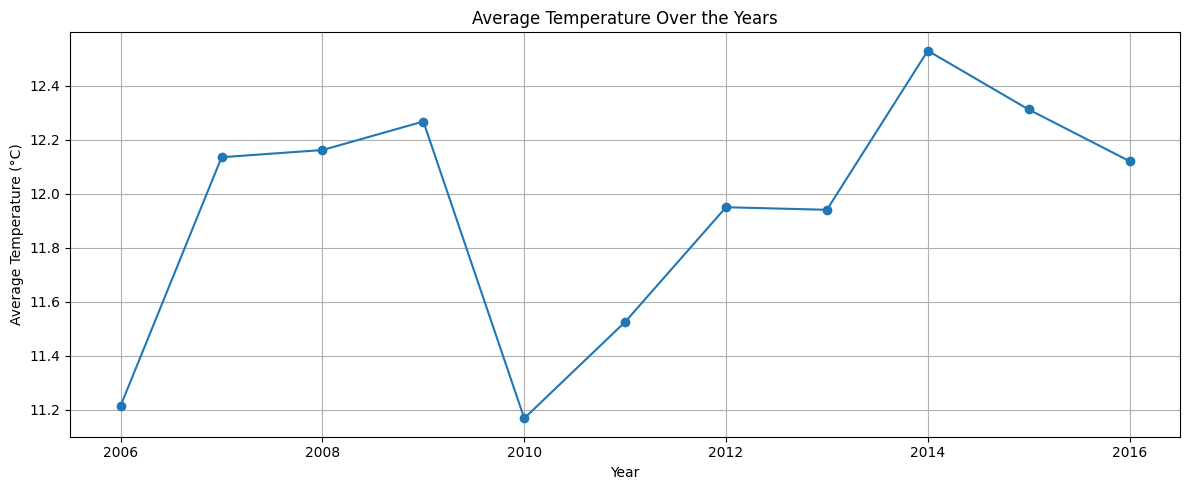

Year
2006    11.22
2007    12.14
2008    12.16
2009    12.27
2010    11.17
2011    11.53
2012    11.95
2013    11.94
2014    12.53
2015    12.31
2016    12.12
Name: Temperature (C), dtype: float64


In [ ]:
yearly_temperature = clean_df.groupby("Year")["Temperature (C)"].mean()

plt.figure(figsize=(12, 5))

yearly_temperature.plot(kind="line", marker="o")

plt.title("Average Temperature Over the Years")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.grid(True)

plt.tight_layout()
plt.show()

print(yearly_temperature.round(2))

The line graph shows the changes in average temperature from 2006 to 2016. The highest yearly average temperature was recorded in 2014 at 12.53°C, while the lowest was recorded in 2010 at 11.17°C. Temperatures fluctuated throughout the period, with no consistent upward or downward trend. Overall, the yearly averages remained relatively close to each other.

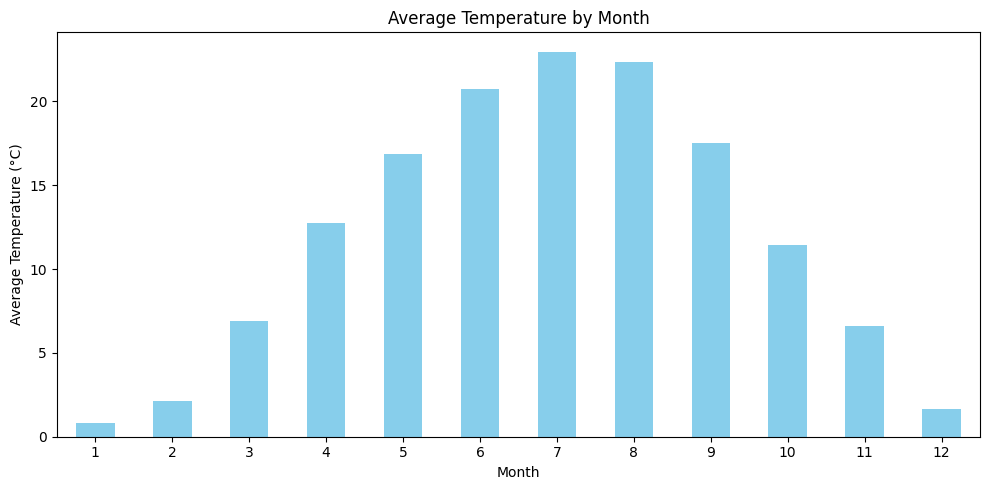

Month
1      0.81
2      2.16
3      6.91
4     12.76
5     16.88
6     20.72
7     22.96
8     22.34
9     17.52
10    11.45
11     6.58
12     1.63
Name: Temperature (C), dtype: float64


In [ ]:
monthly_temperature = clean_df.groupby("Month")["Temperature (C)"].mean()

plt.figure(figsize=(10, 5))

monthly_temperature.plot(
    kind="bar",
    color="skyblue"
)

plt.title("Average Temperature by Month")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

print(monthly_temperature.round(2))

The monthly temperature analysis shows a clear seasonal pattern. July has the highest average temperature at 22.96°C, followed by August at 22.34°C. January is the coldest month, with an average temperature of 0.81°C. Temperatures generally increase from winter towards summer and begin to decrease after July. This indicates noticeable seasonal changes in the dataset.

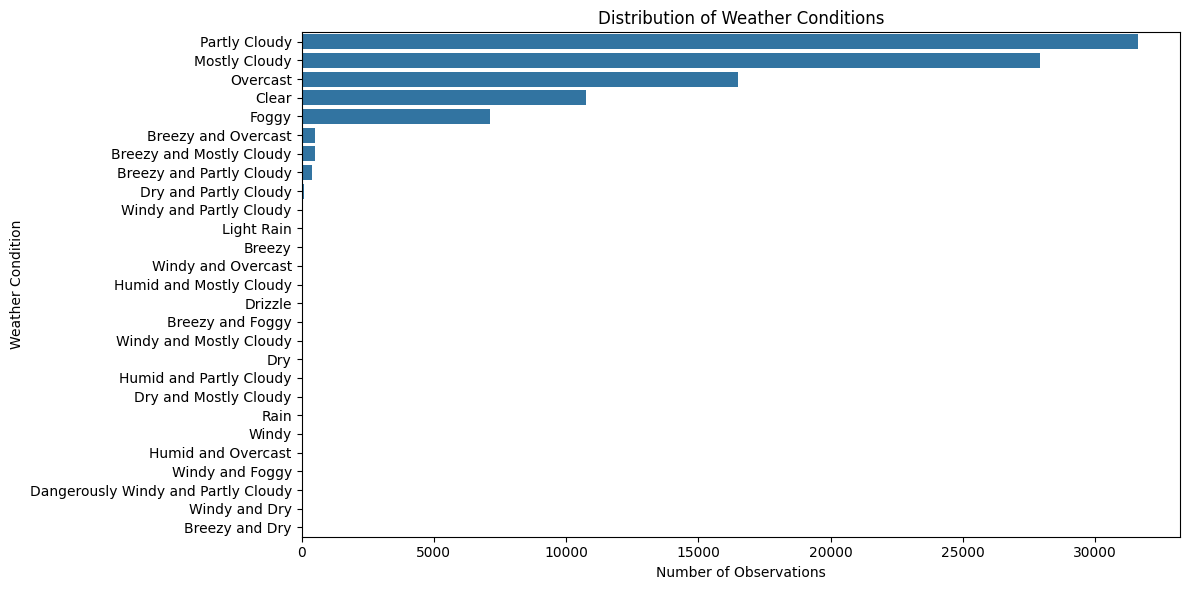

Summary
Partly Cloudy                          31625
Mostly Cloudy                          27913
Overcast                               16514
Clear                                  10746
Foggy                                   7113
Breezy and Overcast                      528
Breezy and Mostly Cloudy                 516
Breezy and Partly Cloudy                 386
Dry and Partly Cloudy                     86
Windy and Partly Cloudy                   67
Light Rain                                63
Breezy                                    54
Windy and Overcast                        45
Humid and Mostly Cloudy                   40
Drizzle                                   39
Breezy and Foggy                          35
Windy and Mostly Cloudy                   35
Dry                                       34
Humid and Partly Cloudy                   17
Dry and Mostly Cloudy                     14
Rain                                      10
Windy                                      8
Hu

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=clean_df,
    y="Summary",
    order=clean_df["Summary"].value_counts().index
)

plt.title("Distribution of Weather Conditions")
plt.xlabel("Number of Observations")
plt.ylabel("Weather Condition")

plt.tight_layout()
plt.show()

print(clean_df["Summary"].value_counts())

The weather condition distribution shows that Partly Cloudy is the most frequently recorded condition, with 31,625 observations, followed by Mostly Cloudy with 27,913 observations. Overcast and Clear conditions are also commonly recorded. In comparison, conditions such as Rain and Drizzle occur less frequently. Dangerously Windy and Partly Cloudy is the least frequent condition, with only one observation. Overall, cloudy and partly cloudy conditions dominate the dataset.

Conclusion:

This analysis explored historical weather data from 2006 to 2016 using different data analysis and visualization techniques. The results showed that the average temperature was approximately 11.94°C, while humidity averaged around 73.5%. Temperature and humidity had a negative relationship, whereas actual and apparent temperature had a very strong positive relationship. Monthly analysis showed that July was the warmest month and January was the coldest. Partly Cloudy was the most frequently recorded weather condition. Overall, the analysis helped us understand temperature patterns, humidity levels, wind speed variations and seasonal weather changes over time.